# Proyek Klasifikasi Gambar: Animals-10 Dataset
- **Nama:** Ilham Jaya Saputra
- **Email:** jayailham04@gmail.com
- **ID Dicoding:** Ilhamjayas

## Deskripsi Proyek
Proyek ini melakukan klasifikasi gambar menggunakan dataset **Animals-10** dari Kaggle  
yang berisi **±26.000 gambar** hewan dari **10 kelas** berbeda.  
Model dibangun menggunakan **MobileNetV2** (pretrained ImageNet) sebagai backbone, dibungkus dalam arsitektur **Sequential** dengan **Conv2D** dan **Pooling Layer** tambahan — memenuhi Kriteria 4 Dicoding.

| Kelas | Kelas | Kelas | Kelas | Kelas |
|-------|-------|-------|-------|-------|
| dog | cat | horse | spider | butterfly |
| chicken | sheep | cow | squirrel | elephant |


## 1. Import Library


In [1]:
# ================================================================
# IMPORT SEMUA LIBRARY
# ================================================================
import os
import shutil
import zipfile
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

# TensorFlow & Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau,
    ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report

from PIL import Image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow : {tf.__version__}')
print(f'Keras      : {keras.__version__}')
print(f'GPU        : {tf.config.list_physical_devices("GPU")}')


TensorFlow : 2.20.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading
### 2.1 Setup Kaggle API & Download Dataset


In [2]:
from google.colab import files
{'kaggle.json': b'{"username":"ilhamjayasaputra","key":"d8b110e4653282ceb63884482b78c358"}'}


{'kaggle.json': b'{"username":"ilhamjayasaputra","key":"d8b110e4653282ceb63884482b78c358"}'}

In [3]:
# Setup direktori Kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print('Kaggle API siap!')


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API siap!


In [4]:
# Download & ekstrak dataset Animals-10
!kaggle datasets download -d alessiocorrado99/animals10

EXTRACT_DIR = '/content/animals10'
with zipfile.ZipFile('animals10.zip', 'r') as z:
    z.extractall(EXTRACT_DIR)

print('Ekstraksi selesai!')
print(os.listdir(EXTRACT_DIR))


Dataset URL: https://www.kaggle.com/datasets/alessiocorrado99/animals10
License(s): GPL-2.0
animals10.zip: Skipping, found more recently modified local copy (use --force to force download)
Ekstraksi selesai!
['translate.py', 'raw-img']


### 2.2 Eksplorasi Dataset


In [5]:
# Folder raw-img berisi nama kelas dalam bahasa Italia
RAW_DATA_DIR = '/content/animals10/raw-img'

# Mapping: nama Italia → nama Inggris
TRANSLATE = {
    'cane'      : 'dog',
    'cavallo'   : 'horse',
    'elefante'  : 'elephant',
    'farfalla'  : 'butterfly',
    'gallina'   : 'chicken',
    'gatto'     : 'cat',
    'mucca'     : 'cow',
    'pecora'    : 'sheep',
    'ragno'     : 'spider',
    'scoiattolo': 'squirrel',
}

VALID_EXT = ('.jpg', '.jpeg', '.png', '.gif', '.JPG', '.JPEG', '.PNG')

# Buat DataFrame semua path gambar + label
filepaths, labels = [], []
class_counts = {}

print(f"{'Kelas':<15} {'Jumlah Gambar':>15}")
print('-' * 32)
for folder_it, folder_en in TRANSLATE.items():
    folder_path = os.path.join(RAW_DATA_DIR, folder_it)
    if not os.path.exists(folder_path):
        continue
    imgs = [f for f in os.listdir(folder_path) if f.lower().endswith(VALID_EXT)]
    for img in imgs:
        filepaths.append(os.path.join(folder_path, img))
        labels.append(folder_en)
    class_counts[folder_en] = len(imgs)
    print(f"{folder_en:<15} {len(imgs):>15,}")

print('-' * 32)
print(f"{'TOTAL':<15} {len(filepaths):>15,}")

# Simpan ke DataFrame
df = pd.DataFrame({'filepath': filepaths, 'label': labels})
print(f'\nShape DataFrame: {df.shape}')
df.head()


Kelas             Jumlah Gambar
--------------------------------
dog                       4,863
horse                     2,623
elephant                  1,446
butterfly                 2,112
chicken                   3,098
cat                       1,668
cow                       1,866
sheep                     1,820
spider                    4,821
squirrel                  1,862
--------------------------------
TOTAL                    26,179

Shape DataFrame: (26179, 2)


,filepath,label
0,/content/animals10/raw-img/cane/OIP-vVXO5rU68N...,dog
1,/content/animals10/raw-img/cane/OIP-I4C6RRhYt9...,dog
2,/content/animals10/raw-img/cane/OIP-alyqL-FB25...,dog
3,/content/animals10/raw-img/cane/OIP-9_oVm9ssR5...,dog
4,/content/animals10/raw-img/cane/OIP-16Mqc38MKB...,dog


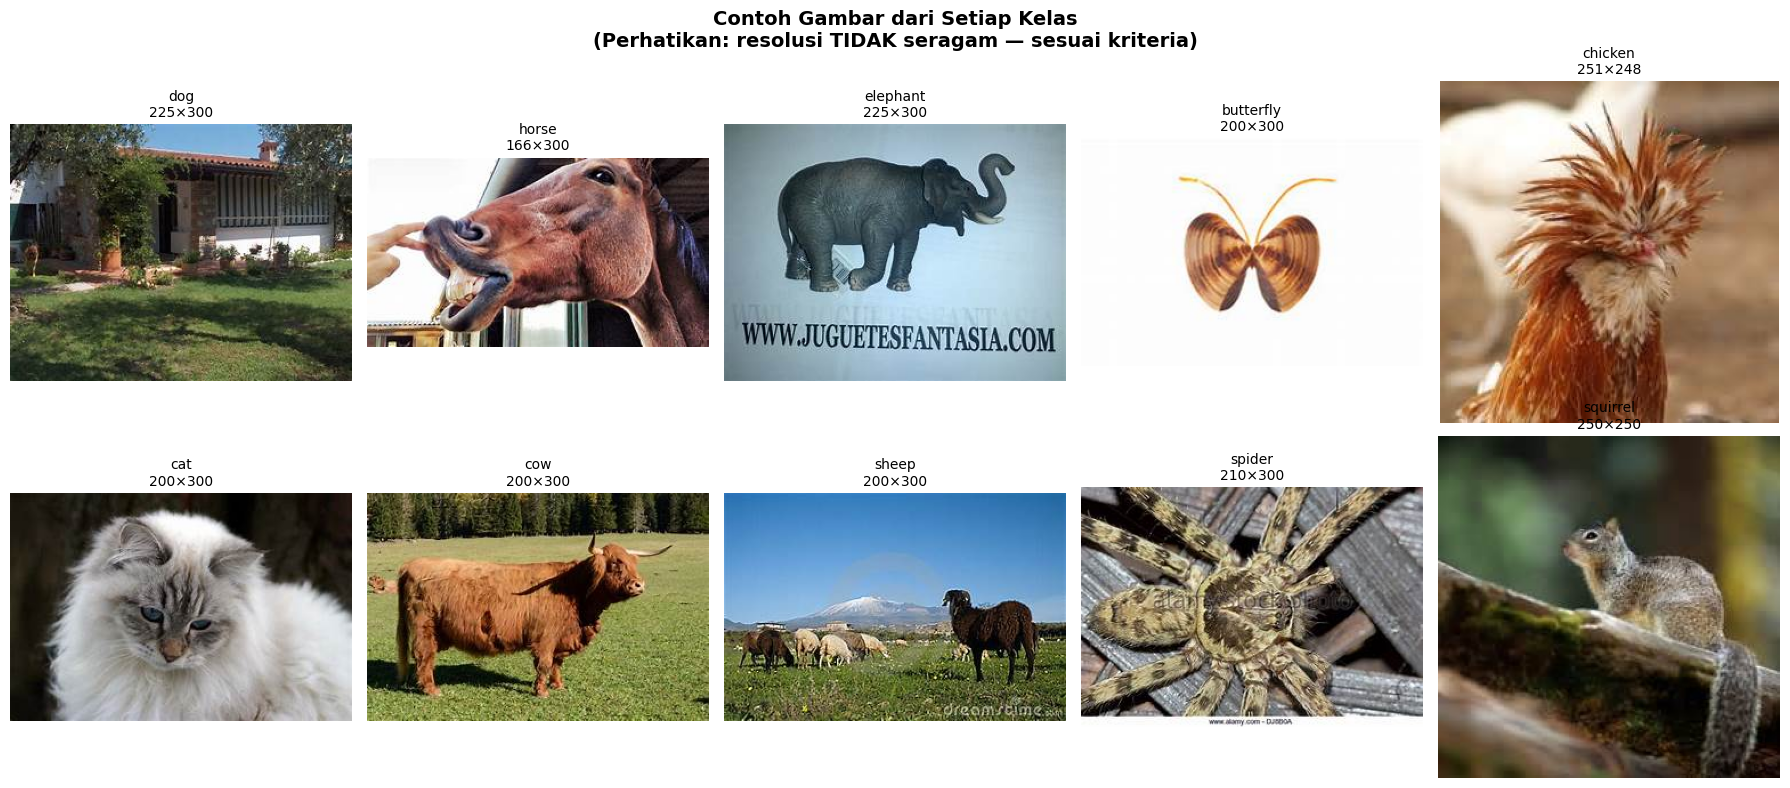

In [7]:
# Visualisasi contoh gambar dari setiap kelas (resolusi tidak seragam)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
fig.suptitle(
    'Contoh Gambar dari Setiap Kelas\n'
    '(Perhatikan: resolusi TIDAK seragam — sesuai kriteria)',
    fontsize=14, fontweight='bold'
)

for idx, (folder_it, folder_en) in enumerate(TRANSLATE.items()):
    folder_path = os.path.join(RAW_DATA_DIR, folder_it)
    imgs = [f for f in os.listdir(folder_path) if f.lower().endswith(VALID_EXT)]
    img_path = os.path.join(folder_path, random.choice(imgs))
    img = mpimg.imread(img_path)
    ax = axes[idx // 5][idx % 5]
    ax.imshow(img)
    ax.set_title(f'{folder_en}\n{img.shape[0]}×{img.shape[1]}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()


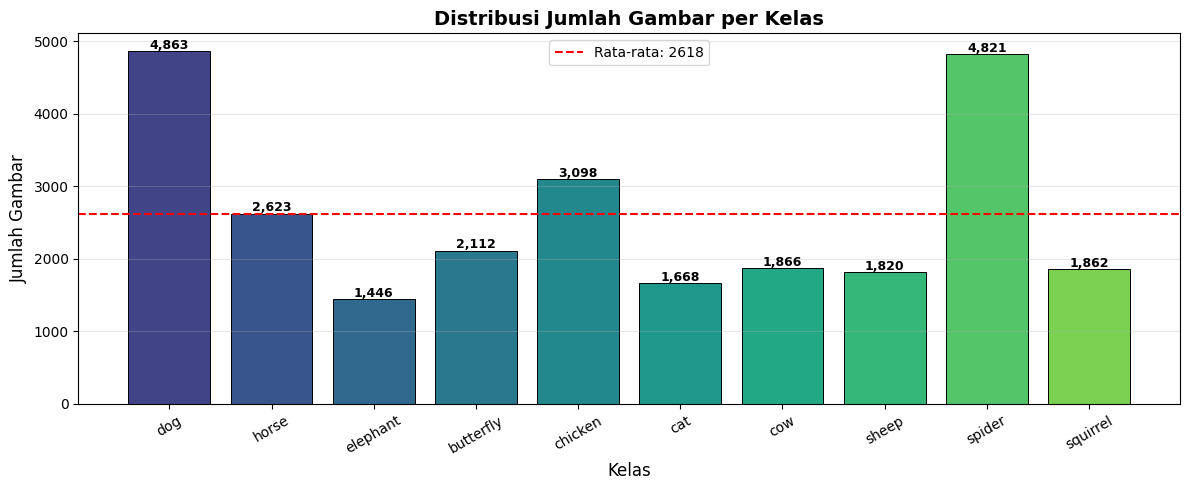

In [8]:
# ── Distribusi kelas ──
fig, ax = plt.subplots(figsize=(12, 5))
classes = list(class_counts.keys())
counts  = list(class_counts.values())
colors  = plt.cm.viridis(np.linspace(0.2, 0.8, len(classes)))

bars = ax.bar(classes, counts, color=colors, edgecolor='black', linewidth=0.7)
ax.axhline(np.mean(counts), color='red', linestyle='--', linewidth=1.5,
           label=f'Rata-rata: {np.mean(counts):.0f}')

for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{c:,}', ha='center', fontweight='bold', fontsize=9)

ax.set_title('Distribusi Jumlah Gambar per Kelas', fontsize=14, fontweight='bold')
ax.set_xlabel('Kelas', fontsize=12)
ax.set_ylabel('Jumlah Gambar', fontsize=12)
ax.tick_params(axis='x', rotation=30)
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Data Preprocessing
### 3.1 Stratified Train / Validation / Test Split


In [6]:
# ================================================================
# Split Dataset:  70% Train | 15% Val | 15% Test
# Menggunakan stratify agar distribusi kelas seimbang di tiap split
# ================================================================

# Tahap 1: 70% train, 30% sisanya
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=SEED
)

# Tahap 2: Bagi 30% menjadi 50/50 → masing-masing 15%
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=SEED
)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

total = len(df)
print('=' * 45)
print(f'  Train : {len(train_df):>6,} gambar ({len(train_df)/total*100:.1f}%)')
print(f'  Val   : {len(val_df):>6,} gambar ({len(val_df)/total*100:.1f}%)')
print(f'  Test  : {len(test_df):>6,} gambar ({len(test_df)/total*100:.1f}%)')
print(f'  Total : {total:>6,} gambar')
print('=' * 45)


  Train : 18,325 gambar (70.0%)
  Val   :  3,927 gambar (15.0%)
  Test  :  3,927 gambar (15.0%)
  Total : 26,179 gambar


### 3.2 Image Data Generator & Augmentasi


In [7]:
# ================================================================
# KONFIGURASI GENERATOR
# ================================================================
IMG_SIZE   = (224, 224)   # MobileNetV2 butuh minimal 96×96, standar 224×224
BATCH_SIZE = 32

# Training: rescale + augmentasi untuk mengurangi overfitting
train_datagen = ImageDataGenerator(
    rescale            = 1./255,
    rotation_range     = 20,
    width_shift_range  = 0.15,
    height_shift_range = 0.15,
    shear_range        = 0.15,
    zoom_range         = 0.15,
    brightness_range   = [0.8, 1.2],
    horizontal_flip    = True,
    fill_mode          = 'nearest'
)

# Validasi & Test: hanya rescale (tanpa augmentasi)
val_test_datagen = ImageDataGenerator(rescale=1./255)

# ── Generator train ──
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col       = 'filepath',
    y_col       = 'label',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = True,
    seed        = SEED
)

# ── Generator validasi ──
val_generator = val_test_datagen.flow_from_dataframe(
    val_df,
    x_col       = 'filepath',
    y_col       = 'label',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = False
)

# ── Generator test ──
test_generator = val_test_datagen.flow_from_dataframe(
    test_df,
    x_col       = 'filepath',
    y_col       = 'label',
    target_size = IMG_SIZE,
    batch_size  = BATCH_SIZE,
    class_mode  = 'categorical',
    shuffle     = False
)

NUM_CLASSES = len(train_generator.class_indices)
CLASS_NAMES = list(train_generator.class_indices.keys())
print(f'Jumlah kelas : {NUM_CLASSES}')
print(f'Nama kelas   : {CLASS_NAMES}')
print(f'Input shape  : {IMG_SIZE + (3,)}')


Found 18325 validated image filenames belonging to 10 classes.
Found 3927 validated image filenames belonging to 10 classes.
Found 3927 validated image filenames belonging to 10 classes.
Jumlah kelas : 10
Nama kelas   : ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']
Input shape  : (224, 224, 3)


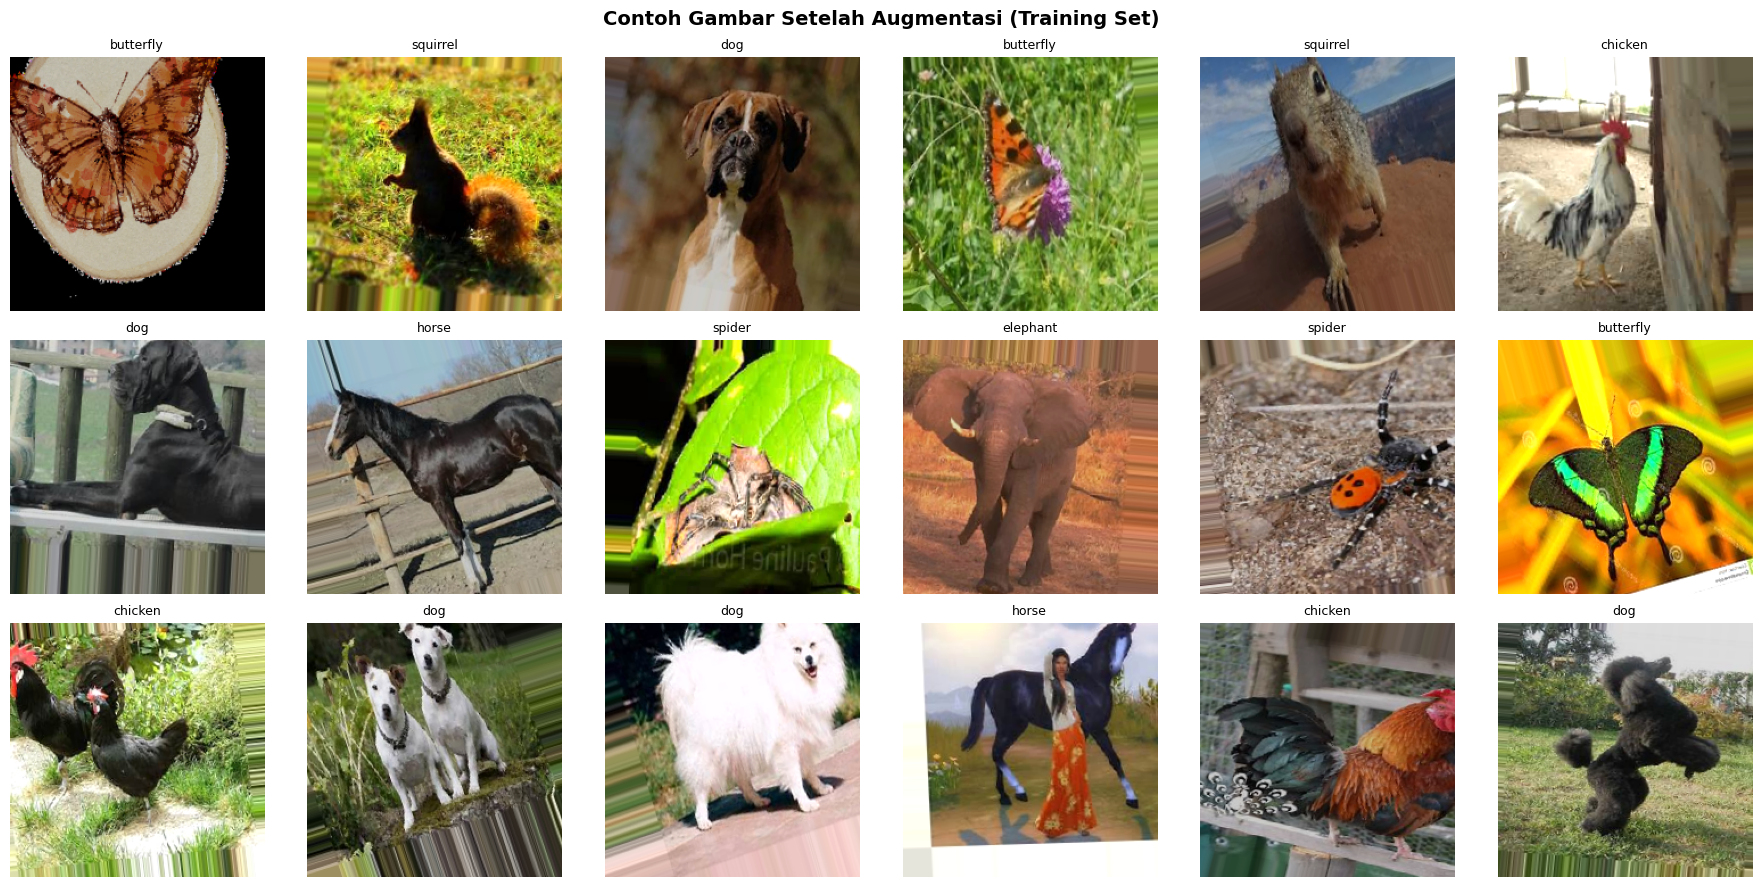

In [8]:
# ── Visualisasi contoh hasil augmentasi ──
batch_imgs, batch_labels = next(train_generator)

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
fig.suptitle('Contoh Gambar Setelah Augmentasi (Training Set)',
             fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < len(batch_imgs):
        ax.imshow(batch_imgs[i])
        ax.set_title(CLASS_NAMES[np.argmax(batch_labels[i])], fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/augmented_samples.png', dpi=150, bbox_inches='tight')
plt.show()


In [9]:
# ── Hitung class weights untuk menangani ketidakseimbangan kelas ──
classes      = np.unique(train_generator.classes)
class_weights = compute_class_weight(
    class_weight = 'balanced',
    classes      = classes,
    y            = train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))

print('Class weights:')
for idx, (name, w) in enumerate(zip(CLASS_NAMES, class_weights)):
    print(f'  [{idx}] {name:<12} : {w:.4f}')


Class weights:
  [0] butterfly    : 1.2399
  [1] cat          : 1.5689
  [2] chicken      : 0.8449
  [3] cow          : 1.4031
  [4] dog          : 0.5383
  [5] elephant     : 1.8108
  [6] horse        : 0.9981
  [7] sheep        : 1.4384
  [8] spider       : 0.5430
  [9] squirrel     : 1.4064


### 4.1 Arsitektur Model — MobileNetV2 + CNN Head


In [10]:
def build_cnn_model(input_shape, num_classes):
    """MobileNetV2 backbone + custom CNN head dalam Sequential."""

    base_model = MobileNetV2(
        weights      = 'imagenet',
        include_top  = False,
        input_shape  = input_shape
    )

    base_model.trainable = True
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    model = Sequential([

        base_model,

        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        GlobalAveragePooling2D(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name='Animals10_MobileNetV2')

    return model


INPUT_SHAPE = IMG_SIZE + (3,)
model = build_cnn_model(INPUT_SHAPE, NUM_CLASSES)

model.compile(
    optimizer = Adam(learning_rate=1e-4),  # LR kecil untuk fine-tuning
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model.summary()


Model: "Animals10_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,106,570 (11.85 MB)

 Trainable params: 2,053,770 (7.83 MB)

 Non-trainable params: 1,052,800 (4.02 MB)

### 4.2 Callbacks


In [11]:
# ================================================================
# DEFINISI CALLBACKS
# ================================================================
early_stopping = EarlyStopping(
    monitor              = 'val_accuracy',
    patience             = 10,
    restore_best_weights = True,
    verbose              = 1,
    mode                 = 'max'
)

reduce_lr = ReduceLROnPlateau(
    monitor  = 'val_loss',
    factor   = 0.3,
    patience = 4,
    min_lr   = 1e-7,
    verbose  = 1
)

os.makedirs('/content/checkpoints', exist_ok=True)
checkpoint = ModelCheckpoint(
    filepath          = '/content/checkpoints/best_model.keras',
    monitor           = 'val_accuracy',
    save_best_only    = True,
    save_weights_only = False,
    verbose           = 1,
    mode              = 'max'
)

class AccuracyThresholdCallback(tf.keras.callbacks.Callback):
    """Hentikan training otomatis saat target akurasi tercapai."""
    def __init__(self, threshold=0.95):
        super().__init__()
        self.threshold = threshold

    def on_epoch_end(self, epoch, logs=None):
        train_acc = logs.get('accuracy', 0)
        val_acc   = logs.get('val_accuracy', 0)
        if train_acc >= self.threshold and val_acc >= self.threshold:
            print(f'\n✅ Target {self.threshold*100:.0f}% tercapai! '
                  f'Train: {train_acc*100:.2f}% | Val: {val_acc*100:.2f}%'
                  f' → Training dihentikan.')
            self.model.stop_training = True

accuracy_callback = AccuracyThresholdCallback(threshold=0.95)

CALLBACKS = [early_stopping, reduce_lr, checkpoint, accuracy_callback]

print('Callbacks yang digunakan:')
for cb in CALLBACKS:
    print(f'  ✔ {cb.__class__.__name__}')


Callbacks yang digunakan:
  ✔ EarlyStopping
  ✔ ReduceLROnPlateau
  ✔ ModelCheckpoint
  ✔ AccuracyThresholdCallback


### 4.3 Training Model


In [12]:
# ================================================================
# TRAINING
# class_weight digunakan agar model tidak bias ke kelas mayoritas
# ================================================================
EPOCHS = 50

history = model.fit(
    train_generator,
    validation_data = val_generator,
    epochs          = EPOCHS,
    class_weight    = class_weights_dict,
    callbacks       = CALLBACKS,
    verbose         = 1
)

Epoch 1/50
163/573 ━━━━━━━━━━━━━━━━━━━━ 3:42 542ms/step - accuracy: 0.3684 - loss: 2.1641

KeyboardInterrupt: 

Maaf tadi kerun lagi karna mau restart session, jadi ini erorr. Untuk modelnya sudah fix tadi

## 5. Evaluasi & Visualisasi
### 5.1 Plot Akurasi & Loss


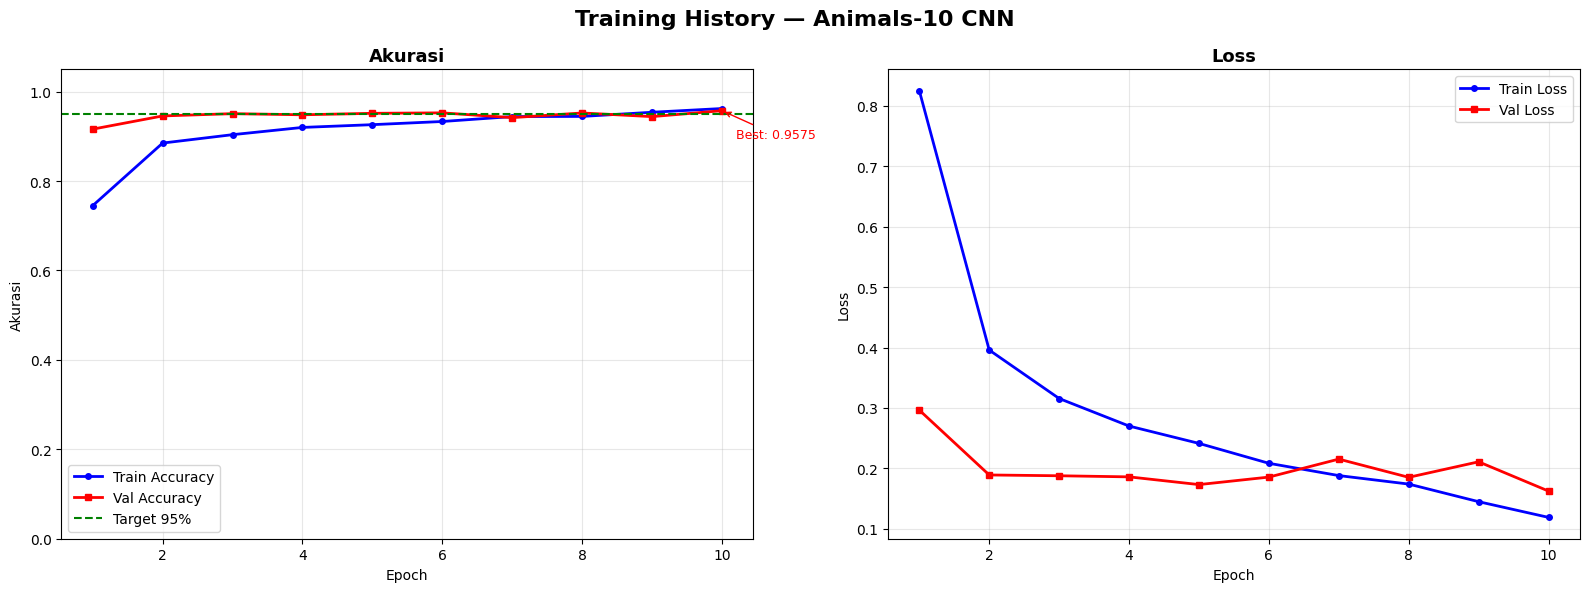

Best Train Accuracy : 0.9623 (96.23%)
Best Val Accuracy   : 0.9575 (95.75%)


In [16]:
# ================================================================
# PLOT HISTORY — Accuracy & Loss
# ================================================================
acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Training History — Animals-10 CNN', fontsize=16, fontweight='bold')

# ── Akurasi ──
axes[0].plot(epochs_range, acc,     'b-o', lw=2, ms=4, label='Train Accuracy')
axes[0].plot(epochs_range, val_acc, 'r-s', lw=2, ms=4, label='Val Accuracy')
axes[0].axhline(y=0.95, color='green', linestyle='--', lw=1.5, label='Target 95%')
axes[0].set_title('Akurasi', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].set_ylim([0, 1.05])
axes[0].legend()
axes[0].grid(True, alpha=0.3)

best_val_epoch = val_acc.index(max(val_acc)) + 1
axes[0].annotate(
    f'Best: {max(val_acc):.4f}',
    xy=(best_val_epoch, max(val_acc)),
    xytext=(10, -20), textcoords='offset points',
    fontsize=9, color='red',
    arrowprops=dict(arrowstyle='->', color='red')
)

# ── Loss ──
axes[1].plot(epochs_range, loss,     'b-o', lw=2, ms=4, label='Train Loss')
axes[1].plot(epochs_range, val_loss, 'r-s', lw=2, ms=4, label='Val Loss')
axes[1].set_title('Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_history.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Best Train Accuracy : {max(acc):.4f} ({max(acc)*100:.2f}%)')
print(f'Best Val Accuracy   : {max(val_acc):.4f} ({max(val_acc)*100:.2f}%)')


### 5.2 Evaluasi pada Test Set


In [17]:
# ================================================================
# LOAD MODEL TERBAIK & EVALUASI PADA TEST SET
# ================================================================
best_model = keras.models.load_model('/content/checkpoints/best_model.keras')
print('✅ Model terbaik berhasil dimuat.')

test_loss, test_acc = best_model.evaluate(test_generator, verbose=1)

print('\n' + '=' * 50)
print('HASIL EVALUASI PADA TEST SET')
print('=' * 50)
print(f'  Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)')
print(f'  Test Loss     : {test_loss:.4f}')
print('=' * 50)

if test_acc >= 0.95:
    print('🏆 Akurasi >= 95% TERCAPAI!')
elif test_acc >= 0.85:
    print('✅ Akurasi >= 85% TERCAPAI (kriteria minimum)!')
else:
    print('⚠️  Akurasi belum memenuhi kriteria minimum 85%.')


✅ Model terbaik berhasil dimuat.
123/123 ━━━━━━━━━━━━━━━━━━━━ 17s 88ms/step - accuracy: 0.9628 - loss: 0.1410

HASIL EVALUASI PADA TEST SET
  Test Accuracy : 0.9628  (96.28%)
  Test Loss     : 0.1410
🏆 Akurasi >= 95% TERCAPAI!


### 5.3 Confusion Matrix & Classification Report


123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 92ms/step
Classification Report:
              precision    recall  f1-score   support

   butterfly       0.95      0.99      0.97       317
         cat       0.93      0.96      0.95       250
     chicken       0.98      0.97      0.97       465
         cow       0.93      0.94      0.93       280
         dog       0.99      0.94      0.96       729
    elephant       0.95      1.00      0.97       217
       horse       0.94      0.97      0.95       394
       sheep       0.95      0.95      0.95       273
      spider       0.99      0.97      0.98       723
    squirrel       0.93      0.99      0.96       279

    accuracy                           0.96      3927
   macro avg       0.95      0.97      0.96      3927
weighted avg       0.96      0.96      0.96      3927



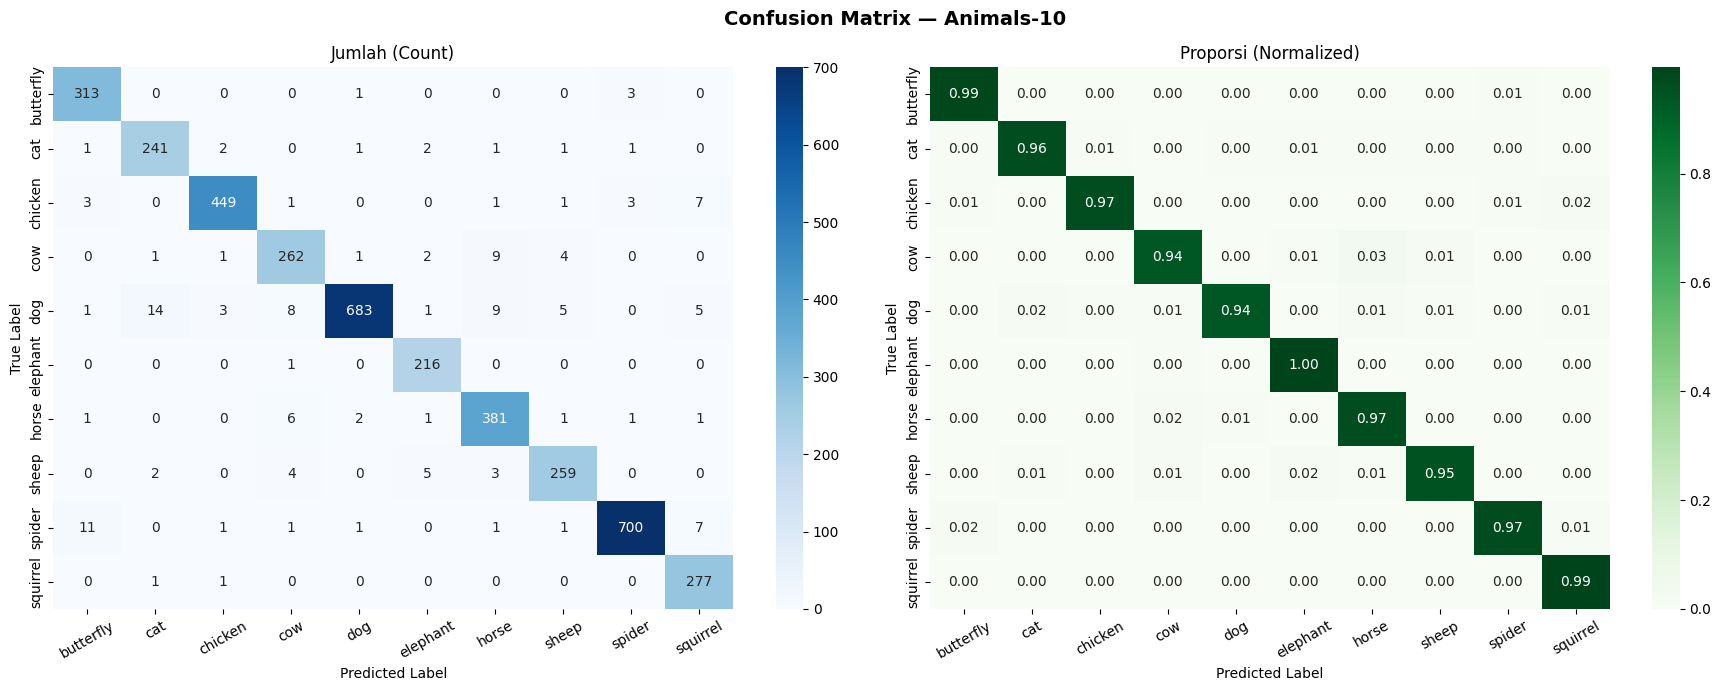

In [18]:
# ================================================================
# CONFUSION MATRIX & CLASSIFICATION REPORT
# ================================================================
test_generator.reset()
y_pred_probs = best_model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)[:len(test_generator.classes)]
y_true = test_generator.classes

print('Classification Report:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# ── Plot Confusion Matrix ──
cm            = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Confusion Matrix — Animals-10', fontsize=14, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Jumlah (Count)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Proporsi (Normalized)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('/content/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Konversi & Penyimpanan Model


In [19]:
# ================================================================
# FORMAT 1 — SavedModel
# ================================================================
SAVED_MODEL_DIR = '/content/saved_model'

print('Menyimpan ke format SavedModel...')
best_model.export(SAVED_MODEL_DIR)

print('\nStruktur SavedModel:')
for root, dirs, files in os.walk(SAVED_MODEL_DIR):
    indent = ' ' * 2 * root.replace(SAVED_MODEL_DIR, '').count(os.sep)
    print(f'{indent}{os.path.basename(root)}/')
    for f in files:
        size = os.path.getsize(os.path.join(root, f)) / 1024 / 1024
        print(f'{indent}  {f}  ({size:.2f} MB)')

print('\n✅ SavedModel berhasil disimpan!')


Menyimpan ke format SavedModel...
Saved artifact at '/content/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  137680705440080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705442960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705443536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705442192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705447376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705441232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705441808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705443344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705447952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137680705443728: TensorSpec(shape=(), dtype=

In [20]:
# ================================================================
# FORMAT 2 — TF-Lite (dengan Dynamic Range Quantization)
# ================================================================
TFLITE_PATH = '/content/model.tflite'

print('Mengkonversi ke TF-Lite...')
converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()
with open(TFLITE_PATH, 'wb') as f:
    f.write(tflite_model)

saved_size  = sum(
    os.path.getsize(os.path.join(r, f))
    for r, _, fs in os.walk(SAVED_MODEL_DIR) for f in fs
) / 1024 / 1024
tflite_size = os.path.getsize(TFLITE_PATH) / 1024 / 1024

print(f'SavedModel : {saved_size:.2f} MB')
print(f'TF-Lite    : {tflite_size:.2f} MB')
print(f'Kompresi   : {(1 - tflite_size/saved_size)*100:.1f}%')
print('\n✅ TF-Lite berhasil disimpan!')


Mengkonversi ke TF-Lite...
SavedModel : 25.50 MB
TF-Lite    : 3.21 MB
Kompresi   : 87.4%

✅ TF-Lite berhasil disimpan!


In [27]:
# ================================================================
# INSTALL tensorflowjs
# ================================================================
import tensorflow as tf
tf_version = tf.__version__
print(f"TensorFlow versi saat ini: {tf_version}")

# Install tensorflowjs versi yang kompatibel dengan TF yang ada
!pip install tensorflowjs==4.22.0 -q

print("✅ tensorflowjs berhasil diinstall!")

TensorFlow versi saat ini: 2.20.0
✅ tensorflowjs berhasil diinstall!


In [30]:
!pip install tensorflowjs==4.21.0 --quiet --no-deps
!pip install tensorflow-hub --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 5.4 MB/s eta 0:00:00


In [31]:
import os

# Pastikan saved_model ada dulu
SAVED_MODEL_DIR = '/content/saved_model'
TFJS_DIR = '/content/tfjs_model'
os.makedirs(TFJS_DIR, exist_ok=True)

# Cek saved_model ada
if os.path.exists(SAVED_MODEL_DIR):
    print("✅ SavedModel ditemukan, lanjut konversi...")
    !tensorflowjs_converter \
        --input_format=tf_saved_model \
        --output_format=tfjs_graph_model \
        {SAVED_MODEL_DIR} \
        {TFJS_DIR}
else:
    print("❌ SavedModel tidak ada, ekspor dulu:")
    import tensorflow as tf
    best_model = tf.keras.models.load_model('/content/checkpoints/best_model.keras')
    best_model.export(SAVED_MODEL_DIR)
    print("✅ Export selesai, jalankan cell ini lagi")

✅ SavedModel ditemukan, lanjut konversi...
2026-05-11 17:26:27.270780: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778520387.383185   23140 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778520387.419004   23140 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778520387.520203   23140 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778520387.526555   23140 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778520387.526595   23140 comput

In [33]:
# Define ulang semua path yang dibutuhkan
import os, zipfile

SAVED_MODEL_DIR = '/content/saved_model'
TFLITE_PATH     = '/content/model.tflite'
TFJS_DIR        = '/content/tfjs_model'
OUTPUT_ZIP      = '/content/animals10_models.zip'

# Cek semua file ada
print("Cek file:")
print(f"  SavedModel : {'✅' if os.path.exists(SAVED_MODEL_DIR) else '❌'} {SAVED_MODEL_DIR}")
print(f"  TF-Lite    : {'✅' if os.path.exists(TFLITE_PATH) else '❌'} {TFLITE_PATH}")
print(f"  TFJS       : {'✅' if os.path.exists(TFJS_DIR) else '❌'} {TFJS_DIR}")

Cek file:
  SavedModel : ✅ /content/saved_model
  TF-Lite    : ✅ /content/model.tflite
  TFJS       : ✅ /content/tfjs_model


In [34]:
# ================================================================
# ZIP SEMUA MODEL UNTUK DIUNDUH
# ================================================================
OUTPUT_ZIP = '/content/animals10_models.zip'

with zipfile.ZipFile(OUTPUT_ZIP, 'w', zipfile.ZIP_DEFLATED) as zf:
    # SavedModel
    for root, _, files in os.walk(SAVED_MODEL_DIR):
        for f in files:
            fpath   = os.path.join(root, f)
            arcname = os.path.relpath(fpath, '/content')
            zf.write(fpath, arcname)
    # TF-Lite
    zf.write(TFLITE_PATH, 'model.tflite')
    # TFJS
    for f in os.listdir(TFJS_DIR):
        zf.write(os.path.join(TFJS_DIR, f), os.path.join('tfjs_model', f))

zip_size = os.path.getsize(OUTPUT_ZIP) / 1024 / 1024
print(f'ZIP berhasil dibuat: {OUTPUT_ZIP}  ({zip_size:.2f} MB)')

from google.colab import files
files.download(OUTPUT_ZIP)


ZIP berhasil dibuat: /content/animals10_models.zip  (35.81 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Inference dengan TF-Lite


In [36]:
# ================================================================
# INFERENCE MENGGUNAKAN TF-LITE INTERPRETER
# ================================================================

def preprocess_image(img_path, img_size=IMG_SIZE):
    """Load & preprocess gambar untuk inferensi."""
    img       = Image.open(img_path).convert('RGB').resize(img_size)
    img_array = np.array(img, dtype=np.float32) / 255.0
    return np.expand_dims(img_array, axis=0)   # shape: (1, H, W, 3)


def predict_tflite(interpreter, img_path):
    """Jalankan inferensi TF-Lite dan kembalikan array probabilitas."""
    input_details  = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    interpreter.set_tensor(input_details[0]['index'], preprocess_image(img_path))
    interpreter.invoke()
    return interpreter.get_tensor(output_details[0]['index'])[0]


# Load interpreter
interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()
print('✅ TF-Lite Interpreter siap!')

# Ambil 1 gambar per kelas dari test set
sample_images = []
for class_name in CLASS_NAMES:
    class_imgs = test_df[test_df['label'] == class_name]['filepath'].tolist()
    if class_imgs:
        sample_images.append((random.choice(class_imgs), class_name))

print(f'Melakukan inferensi pada {len(sample_images)} gambar...')


✅ TF-Lite Interpreter siap!
Melakukan inferensi pada 10 gambar...


  #  True         Predicted    Confidence  Status
-------------------------------------------------------
  1. butterfly    butterfly       100.00%  ✅
  2. cat          cat              99.85%  ✅
  3. chicken      chicken         100.00%  ✅
  4. cow          horse            95.41%  ❌
  5. dog          dog              99.86%  ✅
  6. elephant     elephant         98.59%  ✅
  7. horse        horse            99.99%  ✅
  8. sheep        sheep            99.96%  ✅
  9. spider       spider           98.34%  ✅
 10. squirrel     squirrel         99.98%  ✅
-------------------------------------------------------
Akurasi Inferensi: 9/10 = 90.0%


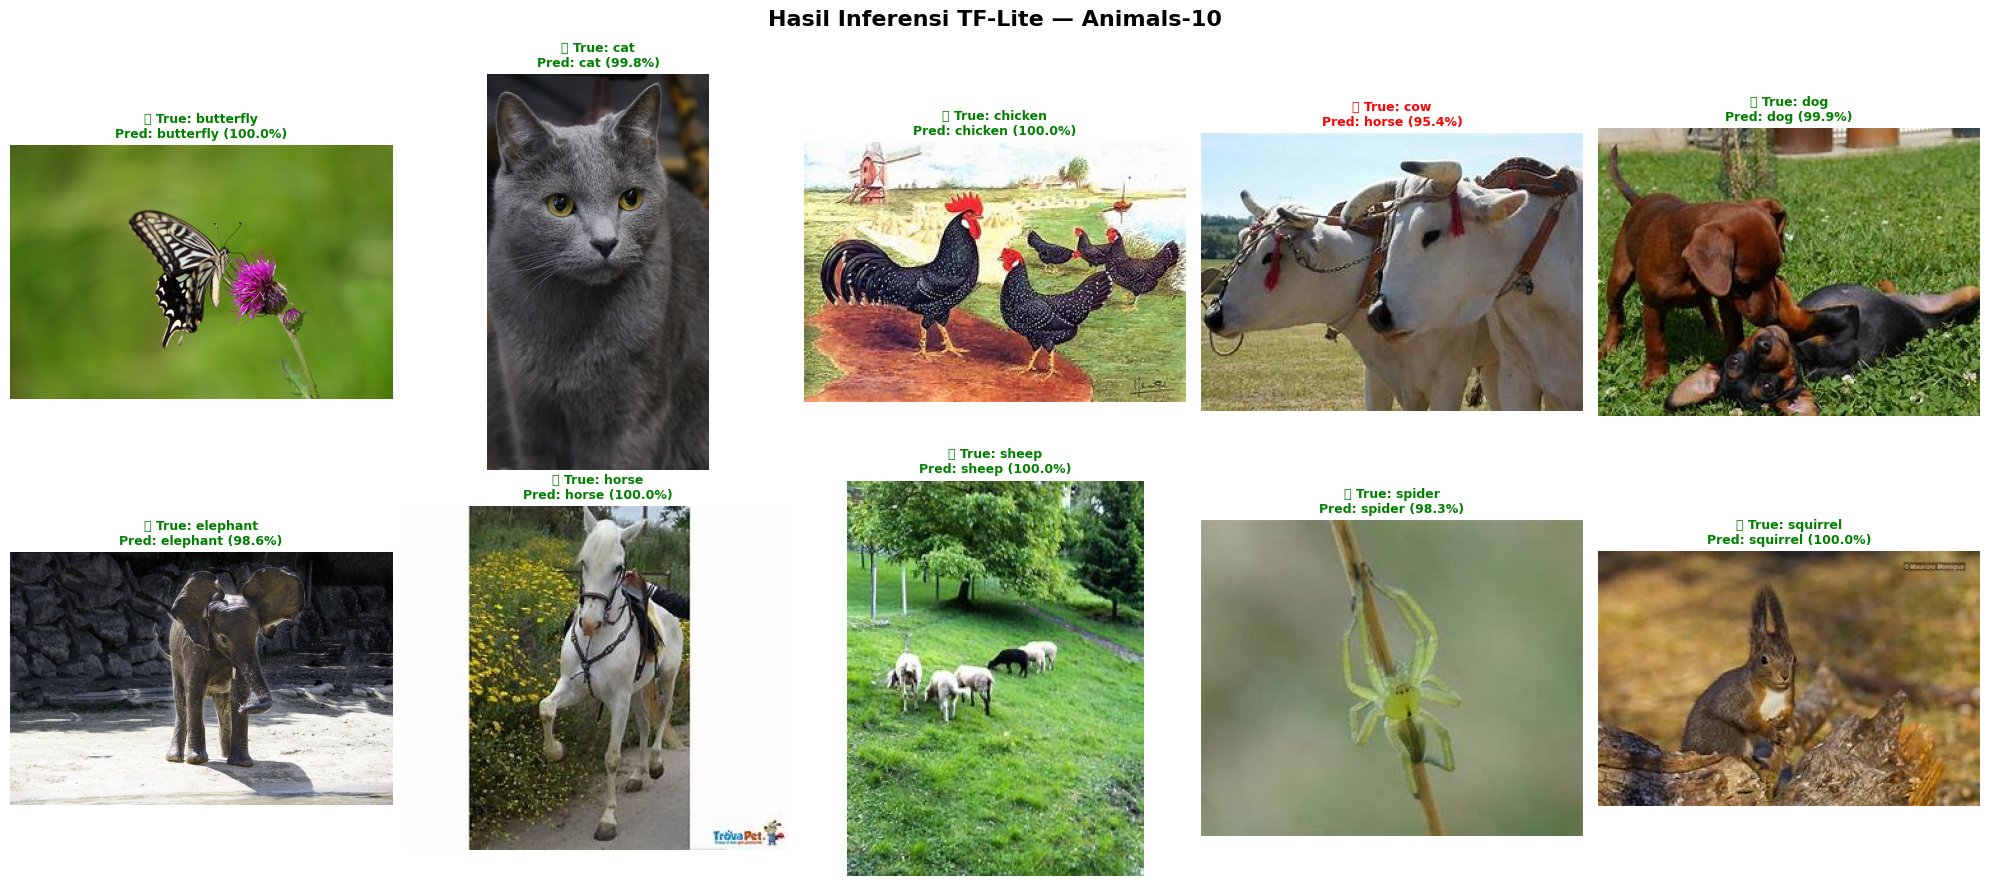


📄 Bukti inferensi tersimpan: /content/inference_results.png


In [37]:
# ── Tampilkan hasil inferensi ──
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
fig.suptitle('Hasil Inferensi TF-Lite — Animals-10', fontsize=16, fontweight='bold')

correct = 0
print(f"{'#':>3}  {'True':<12} {'Predicted':<12} {'Confidence':>10}  Status")
print('-' * 55)

for idx, (img_path, true_label) in enumerate(sample_images):
    probs      = predict_tflite(interpreter, img_path)
    pred_idx   = np.argmax(probs)
    pred_label = CLASS_NAMES[pred_idx]
    confidence = probs[pred_idx] * 100
    is_correct = (pred_label == true_label)
    if is_correct:
        correct += 1

    ax = axes[idx // 5][idx % 5]
    ax.imshow(Image.open(img_path).convert('RGB'))
    color = 'green' if is_correct else 'red'
    icon  = '✅' if is_correct else '❌'
    ax.set_title(
        f'{icon} True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)',
        fontsize=9, color=color, fontweight='bold'
    )
    ax.axis('off')

    print(f"{idx+1:>3}. {true_label:<12} {pred_label:<12} {confidence:>9.2f}%  {icon}")

print('-' * 55)
print(f'Akurasi Inferensi: {correct}/{len(sample_images)} = {correct/len(sample_images)*100:.1f}%')

plt.tight_layout()
plt.savefig('/content/inference_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n📄 Bukti inferensi tersimpan: /content/inference_results.png')
